<a href="https://colab.research.google.com/github/gpu004/cv-project2/blob/main/CV_Project2_Q1-Q4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CS-GY-6643 computer vision, project 2, questions 1 to 4

**Name / NetID:** _fill in_

Classical methods only. Colour and texture filters, edge and line fits, SIFT with RANSAC homographies, a cylindrical projection, superpixels, and GrabCut. No learned models, no hand-drawn labels, no hard-coded object locations or transforms, and no call to `cv2.Stitcher`.

Run the notebook from the top with Restart and run all. The setup cell downloads the four Drive folders into `data/q1` through `data/q4`. Each figure is written to `outputs/qN/` and shown under the cell that produced it.


In [10]:
import shutil
from pathlib import Path

import cv2
import gdown
import numpy as np
import skimage

downloads = [
    (
        "data/q1",
        "https://drive.google.com/drive/folders/1k8hI7fzsFbQjLormykYMNexBWOQWG95I",
        ("Runway.jpg",),
    ),
    (
        "data/q2",
        "https://drive.google.com/drive/folders/1GvVYEa3E-fRXkHfTyT1CpwSrpRZJtiUp",
        ("Scene.png", "Source_Screen.png", "replacement_screen.jpg"),
    ),
    (
        "data/q3",
        "https://drive.google.com/drive/folders/1KvzEp2Ny-F_k9ZU_G4O9ouc6OTcbBdWJ",
        tuple(f"Q3_Image_{index}.jpg" for index in range(1, 7)),
    ),
    (
        "data/q4",
        "https://drive.google.com/drive/folders/1m2ayUNDVZH7ZRoKVUph7WO4Gcd9nvV3N",
        (
            *tuple(f"Q4_Image_{index}.jpg" for index in range(1, 4)),
            "clicks.json",
        ),
    ),
]

for directory, url, expected_files in downloads:
    target = Path(directory)
    if not target.exists():
        target.parent.mkdir(parents=True, exist_ok=True)
        gdown.download_folder(url, output=directory, quiet=True)
    if target.exists():
        nested_files = sorted(path for path in target.rglob("*") if path.is_file())
        for nested_file in nested_files:
            if nested_file.parent != target:
                destination = target / nested_file.name
                if not destination.exists():
                    shutil.move(str(nested_file), str(destination))
        nested_directories = sorted(
            (path for path in target.rglob("*") if path.is_dir()),
            key=lambda path: len(path.parts),
            reverse=True,
        )
        for nested_directory in nested_directories:
            if not any(nested_directory.iterdir()):
                nested_directory.rmdir()
    missing = [name for name in expected_files if not (target / name).is_file()]
    assert not missing, f"Missing expected files in {target}: {missing}"

print(f"OpenCV: {cv2.__version__}")
print(f"NumPy: {np.__version__}")
print(f"scikit-image: {skimage.__version__}")

OpenCV: 5.0.0
NumPy: 2.1.3
scikit-image: 0.25.2


## Question 1, runway boundaries

I need two lines. One on the outer left edge of the pavement, one on the outer right.

Grass is the only saturated green or yellow in the frame. I threshold HSV at `20 < H < 90` and `S > 60`, then close with a 5×5 kernel. The runway starts on the first row where grass covers a large share of the width. Rows above that are sky and distant buildings, so I drop them.

Below that row, pixels that are not grass are runway candidates. A 7×7 opening removes markings and speckle. I keep the largest connected component and close it with a 15×15 kernel, so the centre line and the threshold bars stay inside one region.

Each remaining row contributes its leftmost and rightmost runway pixels. Those samples snap to the strongest horizontal Sobel response within a few pixels. The snap lands on the asphalt to grass transition.

`cv2.fitLine` with a Huber loss fits `x` as a function of `y` on each side. A taxiway join or a painted mark only shoves a few rows, and Huber down-weights them. I draw both lines from the bottom of the image to the far end of the runway, and I print where they meet so I can check that point against the grass-onset row.


left : x = -0.4951*y + 645.7  points 306  mean |res| 2.28px  max |res| 8.44px  within 3px 73.2%
right: x = +0.5078*y + 463.0  points 306  mean |res| 2.02px  max |res| 7.52px  within 3px 74.2%
horizon row (grass onset) y=302, runway rows 307..639
vanishing point of the two boundaries: (555.5, 182.2)
left boundary segment: (329, 639) -> (494, 307)
right boundary segment: (788, 639) -> (619, 307)
Q1 solve runtime: 0.79 s


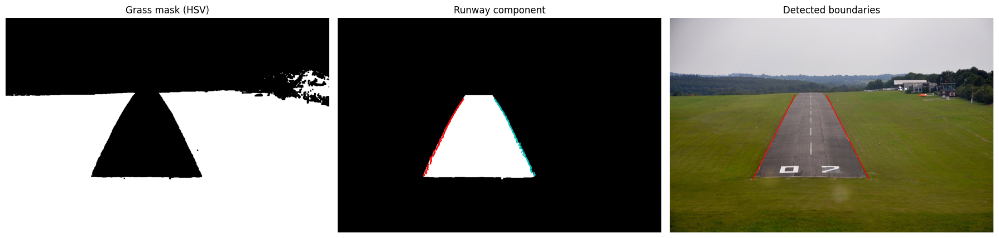

In [11]:
import time
from pathlib import Path
from typing import cast

import cv2
import matplotlib.pyplot as plt
import numpy as np

q1_started = time.perf_counter()

DATA = Path("data/q1")
OUT = Path("outputs/q1")
OUT.mkdir(parents=True, exist_ok=True)


def grass_mask(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    h, s = hsv[..., 0], hsv[..., 1]
    mask = ((h > 20) & (h < 90) & (s > 60)).astype(np.uint8)
    return cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))


def horizon_row(grass):
    rows = grass.mean(axis=1)
    return int(np.argmax(rows > 0.5))


def runway_mask(grass, y_h):
    cand = 1 - grass
    cand[: y_h + 5] = 0
    cand = cv2.morphologyEx(cand, cv2.MORPH_OPEN, np.ones((7, 7), np.uint8))
    _, lab, stats, _ = cv2.connectedComponentsWithStats(cand)
    best = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    mask = (lab == best).astype(np.uint8)
    return cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8))


def side_points(mask):
    ys, left, right = [], [], []
    rows = np.where(mask.any(axis=1))[0]
    y0, y1 = rows.min(), rows.max()
    margin = int(0.04 * (y1 - y0))
    for y in range(y0 + margin, y1 - margin):
        xs = np.where(mask[y])[0]
        ys.append(y)
        left.append(xs.min())
        right.append(xs.max())
    ys = np.array(ys, float)
    return ys, np.array(left, float), np.array(right, float), (y0, y1)


def refine_with_edges(gray, ys, xs, band=6):
    gx = cv2.Sobel(cv2.GaussianBlur(gray, (5, 5), 0), cv2.CV_32F, 1, 0, ksize=3)
    out = []
    for y, x in zip(ys.astype(int), xs.astype(int), strict=True):
        lo, hi = max(x - band, 0), min(x + band + 1, gray.shape[1])
        out.append(lo + np.argmax(np.abs(gx[y, lo:hi])))
    return np.array(out, float)


def robust_line(ys, xs):
    pts = np.c_[xs, ys].astype(np.float32)
    vx, vy, x0, y0 = cv2.fitLine(pts, cv2.DIST_HUBER, 0, 0.01, 0.01).ravel()
    a = vx / vy
    b = x0 - a * y0
    resid = np.abs(xs - (a * ys + b))
    return a, b, resid


img = cast(np.ndarray, cv2.imread(str(DATA / "Runway.jpg")))
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
grass = grass_mask(img)
y_h = horizon_row(grass)
runway = runway_mask(grass, y_h)
ys, xl, xr, (y_top, y_bot) = side_points(runway)
xl_ref = refine_with_edges(gray, ys, xl)
xr_ref = refine_with_edges(gray, ys, xr)

lines = {}
for name, xs in [("left", xl_ref), ("right", xr_ref)]:
    a, b, resid = robust_line(ys, xs)
    lines[name] = (a, b)
    print(
        f"{name:5s}: x = {a:+.4f}*y + {b:.1f}  points {len(ys)}  "
        f"mean |res| {resid.mean():.2f}px  max |res| {resid.max():.2f}px  "
        f"within 3px {np.mean(resid < 3):.1%}"
    )

(al, bl), (ar, br) = lines["left"], lines["right"]
y_vp = (br - bl) / (al - ar)
x_vp = al * y_vp + bl
print(f"horizon row (grass onset) y={y_h}, runway rows {y_top}..{y_bot}")
print(f"vanishing point of the two boundaries: ({x_vp:.1f}, {y_vp:.1f})")

endpoints = {}
for name, (a, b) in lines.items():
    p_top = (int(round(a * y_top + b)), int(y_top))
    p_bot = (int(round(a * y_bot + b)), int(y_bot))
    endpoints[name] = (p_top, p_bot)
    print(f"{name} boundary segment: {p_bot} -> {p_top}")

annot = img.copy()
for p_top, p_bot in endpoints.values():
    cv2.line(annot, p_bot, p_top, (0, 0, 255), 2, cv2.LINE_AA)
cv2.imwrite(str(OUT / "runway_boundaries.png"), annot)
x0c = max(min(p[0] for p in sum(endpoints.values(), ())) - 40, 0)
x1c = max(p[0] for p in sum(endpoints.values(), ())) + 40
cv2.imwrite(
    str(OUT / "runway_boundaries_zoom.png"),
    annot[max(y_top - 20, 0) : y_bot + 20, x0c:x1c],
)

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ax[0].imshow(grass, cmap="gray")
ax[0].set_title("Grass mask (HSV)")
ax[1].imshow(runway, cmap="gray")
ax[1].set_title("Runway component")
ax[1].plot(xl_ref, ys, "r.", ms=1)
ax[1].plot(xr_ref, ys, "c.", ms=1)
ax[2].imshow(cv2.cvtColor(annot, cv2.COLOR_BGR2RGB))
ax[2].set_title("Detected boundaries")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.savefig(OUT / "pipeline.png", dpi=110)

print(f"Q1 solve runtime: {time.perf_counter() - q1_started:.2f} s")

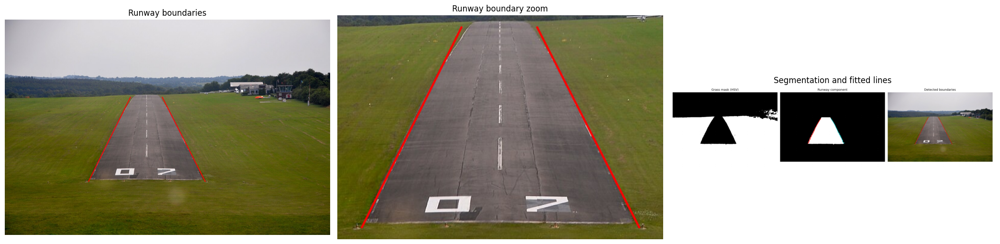

In [12]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
from IPython.display import display


def _read_q1_display(path, max_side=1600):
    image = plt.imread(path)
    scale = min(1.0, max_side / max(image.shape[:2]))
    if scale < 1.0:
        image = cv2.resize(
            image,
            (round(image.shape[1] * scale), round(image.shape[0] * scale)),
            interpolation=cv2.INTER_AREA,
        )
    return image


items = [
    ("Runway boundaries", Path("outputs/q1/runway_boundaries.png")),
    ("Runway boundary zoom", Path("outputs/q1/runway_boundaries_zoom.png")),
    ("Segmentation and fitted lines", Path("outputs/q1/pipeline.png")),
]
figure, axes = plt.subplots(1, 3, figsize=(21, 7))
for axis, (title, path) in zip(axes, items, strict=True):
    axis.imshow(_read_q1_display(path))
    axis.set_title(title)
    axis.axis("off")
figure.tight_layout()
display(figure)
plt.close(figure)

### Results

Left line, `x = −0.4951·y + 645.7`. Right line, `x = +0.5078·y + 463.0`. 306 samples on each side.

Mean absolute residual is 2.28 px on the left and 2.02 px on the right. 73 to 74 percent of the samples land within 3 px of the line. Residuals around 2 px are a straight edge.

The lines meet at x = 555.5, y = 182.2. Grass onset is at y ≈ 302, so the meeting point is above the horizon and near the middle of the frame. Parallel edges from the approach should meet there.

The lines follow the outer pavement. Samples come from the mask boundary, so the centre line and the threshold bars stay out of the fit. A Hough transform on the raw image locks onto those markings.

The runway has to be the largest non-grass region under the horizon, and the edges have to be straight. A curved taxiway breaks the line fit. Snow on the grass breaks the HSV threshold.


## Question 2, book cover replacement

I replace the Odyssey front cover with the Computer Vision cover, in the same perspective, and leave the spine, the page block, and the desk alone.

SIFT runs on the fronto-parallel reference `Source_Screen.png` and on the scene. Nearest-neighbour matches go through Lowe's ratio test, and ambiguous pairs drop out. `cv2.findHomography` estimates the 3×3 map from the reference cover into the scene. The estimator is `USAC_MAGSAC` when this OpenCV build has it, and classic RANSAC otherwise.

The reference photo is cropped a little inside the physical cover, so the projected corners sit inside the real edges and a strip of the old art would show. Along each side of that quad I sample Lab colour outward along the normal, and I keep the offset where the side average jumps the most. Top and side edges jump from cover to desk. The bottom edge jumps from the gold band to the white page block. If nothing beats the jump already on the SIFT edge, that side stays put. I fit a robust line to the edge points on each side. The four lines cross at the refined quad.

`cv2.warpPerspective` maps the replacement from its own corners onto that quad. I replace only the pixels inside the quad, and I copy the rest from the scene. The outline has a 1 to 2 px anti-aliased blend.


In [13]:
import time
from pathlib import Path
from typing import Any as Q2Any
from typing import cast

import cv2
import numpy as np

q2_started = time.perf_counter()

DATA = Path("data/q2")
OUT = Path("outputs/q2")


def cross2d(first, second):
    return first[0] * second[1] - first[1] * second[0]


def resize_long_side(image, limit):
    scale = min(1.0, limit / max(image.shape[:2]))
    size = (round(image.shape[1] * scale), round(image.shape[0] * scale))
    return cv2.resize(image, size, interpolation=cv2.INTER_AREA), scale


def estimate_homography(source, scene):
    source_small, source_scale = resize_long_side(source, 1200)
    scene_small, scene_scale = resize_long_side(scene, 2000)
    source_gray = cv2.cvtColor(source_small, cv2.COLOR_BGR2GRAY)
    scene_gray = cv2.cvtColor(scene_small, cv2.COLOR_BGR2GRAY)
    sift = cast(Q2Any, cv2).SIFT_create(nfeatures=7000)
    keypoints_source, descriptors_source = sift.detectAndCompute(source_gray, None)
    keypoints_scene, descriptors_scene = sift.detectAndCompute(scene_gray, None)
    pairs = cv2.BFMatcher(cv2.NORM_L2).knnMatch(
        descriptors_source, descriptors_scene, k=2
    )
    good = [first for first, second in pairs if first.distance < 0.75 * second.distance]
    if len(good) < 4:
        raise RuntimeError(
            f"Only {len(good)} ratio-test matches; at least four are required."
        )

    points_source = np.asarray(
        [keypoints_source[m.queryIdx].pt for m in good], dtype=np.float32
    )
    points_scene = np.asarray(
        [keypoints_scene[m.trainIdx].pt for m in good], dtype=np.float32
    )
    homography, inlier_mask = cv2.findHomography(
        points_source,
        points_scene,
        cv2.USAC_MAGSAC,
        3.0,
        maxIters=10000,
        confidence=0.999,
    )
    if homography is None or inlier_mask is None:
        raise RuntimeError("Homography estimation failed.")

    inliers = inlier_mask.ravel().astype(bool)
    projected = cv2.perspectiveTransform(points_source[inliers, None, :], homography)[
        :, 0
    ]
    errors = np.linalg.norm(projected - points_scene[inliers], axis=1)
    source_to_small = np.diag([source_scale, source_scale, 1.0])
    scene_to_full = np.diag([1.0 / scene_scale, 1.0 / scene_scale, 1.0])
    homography_full = scene_to_full @ homography @ source_to_small
    return {
        "homography": homography_full,
        "source_small": source_small,
        "scene_small": scene_small,
        "keypoints_source": keypoints_source,
        "keypoints_scene": keypoints_scene,
        "good": good,
        "inliers": inliers,
        "errors": errors,
        "scene_scale": scene_scale,
    }


def line_intersection(first, second):
    point_a, direction_a = first
    point_b, direction_b = second
    denominator = cross2d(direction_a, direction_b)
    if abs(denominator) < 1e-6:
        raise RuntimeError("Refined cover edges are nearly parallel.")
    scale = cross2d(point_b - point_a, direction_b) / denominator
    return point_a + scale * direction_a


def refine_quad_edges(scene, corners):
    lab = cv2.cvtColor(scene, cv2.COLOR_BGR2LAB).astype(np.float32)
    lab = cv2.GaussianBlur(lab, (0, 0), sigmaX=2.0, sigmaY=2.0)
    offsets = np.arange(-20, 103, dtype=np.float32)
    side_names = ("top", "right", "bottom", "left")
    center = corners.mean(axis=0)
    lines = []
    diagnostics = []

    for index, side_name in enumerate(side_names):
        start = corners[index]
        end = corners[(index + 1) % 4]
        direction = end - start
        length = np.linalg.norm(direction)
        tangent = direction / max(length, 1e-6)
        normal = np.array([-tangent[1], tangent[0]], dtype=np.float32)
        if np.dot(normal, center - (start + end) / 2) > 0:
            normal = -normal
        fractions = np.linspace(0.08, 0.92, 60, dtype=np.float32)
        samples = start[None, :] + fractions[:, None] * direction
        map_x = (samples[:, None, 0] + offsets[None, :] * normal[0]).astype(np.float32)
        map_y = (samples[:, None, 1] + offsets[None, :] * normal[1]).astype(np.float32)
        profiles = cv2.remap(
            lab, map_x, map_y, cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT101
        )
        mean_profile = profiles.mean(axis=0)
        std_profile = profiles.std(axis=0)

        candidate_offsets = np.arange(0, 91, dtype=np.int32)
        jump_profile = np.zeros(len(candidate_offsets), dtype=np.float32)
        for candidate_index, offset in enumerate(candidate_offsets):
            before = mean_profile[
                offset - 12 - int(offsets[0]) : offset - 3 - int(offsets[0]) + 1
            ]
            after = mean_profile[
                offset + 3 - int(offsets[0]) : offset + 12 - int(offsets[0]) + 1
            ]
            jump_profile[candidate_index] = np.linalg.norm(
                after.mean(axis=0) - before.mean(axis=0)
            )

        best_index = int(np.argmax(jump_profile))
        best_offset = int(candidate_offsets[best_index])
        baseline_jump = float(jump_profile[0])
        best_jump = float(jump_profile[best_index])
        if best_offset > 0 and best_jump < 1.2 * baseline_jump:
            best_offset = 0
            best_jump = baseline_jump

        gradient = np.linalg.norm(profiles[:, 1:] - profiles[:, :-1], axis=2)
        gradient_offsets = (offsets[1:] + offsets[:-1]) / 2
        local = (gradient_offsets >= best_offset - 6) & (
            gradient_offsets <= best_offset + 6
        )
        local_indices = np.flatnonzero(local)
        boundary_points = []
        local_offsets = []
        for sample_index, sample in enumerate(samples):
            profile_gradient = gradient[sample_index, local]
            best_gradient_index = local_indices[int(np.argmax(profile_gradient))]
            boundary_offset = float(gradient_offsets[best_gradient_index])
            boundary_points.append(sample + boundary_offset * normal)
            local_offsets.append(boundary_offset)

        fitted = cv2.fitLine(
            np.asarray(boundary_points, dtype=np.float32).reshape(-1, 1, 2),
            cv2.DIST_HUBER,
            0,
            0.01,
            0.01,
        ).ravel()
        line = (
            np.array([fitted[2], fitted[3]], dtype=np.float32),
            np.array([fitted[0], fitted[1]], dtype=np.float32),
        )
        lines.append(line)
        diagnostics.append(
            {
                "name": side_name,
                "offset": best_offset,
                "jump": best_jump,
                "baseline_jump": baseline_jump,
                "std": float(np.linalg.norm(std_profile.mean(axis=0))),
                "local_offset_median": float(np.median(local_offsets)),
            }
        )

    refined = np.asarray(
        [line_intersection(lines[(index - 1) % 4], lines[index]) for index in range(4)],
        dtype=np.float32,
    )
    if not cv2.isContourConvex(np.round(refined).astype(np.int32)):
        raise RuntimeError("Refined cover boundary is not a convex quadrilateral.")
    return refined, diagnostics


def save_preview(path, image, max_side=1800, quality=93):
    preview, _ = resize_long_side(image, max_side)
    suffix = Path(path).suffix.lower()
    if suffix in (".jpg", ".jpeg"):
        cv2.imwrite(str(path), preview, [cv2.IMWRITE_JPEG_QUALITY, quality])
    else:
        cv2.imwrite(str(path), preview)


def main():
    OUT.mkdir(parents=True, exist_ok=True)
    scene = cv2.imread(str(DATA / "Scene.png"))
    source = cv2.imread(str(DATA / "Source_Screen.png"))
    replacement = cv2.imread(str(DATA / "replacement_screen.jpg"))
    if scene is None or source is None or replacement is None:
        raise FileNotFoundError(f"Could not load all Q2 inputs from {DATA}.")

    result = estimate_homography(source, scene)
    source_h, source_w = source.shape[:2]
    replacement_h, replacement_w = replacement.shape[:2]
    source_corners = np.asarray(
        [[0, 0], [source_w - 1, 0], [source_w - 1, source_h - 1], [0, source_h - 1]],
        dtype=np.float32,
    )
    detected_corners = cv2.perspectiveTransform(
        source_corners[None, :, :], result["homography"]
    )[0]
    refined_corners, side_diagnostics = refine_quad_edges(scene, detected_corners)
    replacement_corners = np.asarray(
        [
            [0, 0],
            [replacement_w - 1, 0],
            [replacement_w - 1, replacement_h - 1],
            [0, replacement_h - 1],
        ],
        dtype=np.float32,
    )
    replacement_to_scene = cv2.getPerspectiveTransform(
        replacement_corners, refined_corners
    )
    replacement_warped = cv2.warpPerspective(
        replacement,
        replacement_to_scene,
        (scene.shape[1], scene.shape[0]),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_CONSTANT,
    )
    mask = np.zeros(scene.shape[:2], dtype=np.uint8)
    cv2.fillConvexPoly(
        mask, np.round(refined_corners).astype(np.int32), 255, lineType=cv2.LINE_AA
    )
    mask = cv2.GaussianBlur(mask, (3, 3), sigmaX=0.5)
    alpha = mask.astype(np.float32)[:, :, None] / 255.0
    augmented = np.clip(
        replacement_warped.astype(np.float32) * alpha
        + scene.astype(np.float32) * (1.0 - alpha),
        0,
        255,
    ).astype(np.uint8)

    good = result["good"]
    inlier_matches = [
        match for match, keep in zip(good, result["inliers"], strict=True) if keep
    ]
    match_vis = cast(Q2Any, cv2).drawMatches(
        result["source_small"],
        result["keypoints_source"],
        result["scene_small"],
        result["keypoints_scene"],
        inlier_matches,
        None,
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS,
    )
    save_preview(OUT / "q2_inlier_matches.jpg", match_vis, max_side=2000)

    scene_outline = scene.copy()
    cv2.polylines(
        scene_outline,
        [np.round(detected_corners).astype(np.int32)],
        True,
        (0, 255, 0),
        8,
        cv2.LINE_AA,
    )
    save_preview(OUT / "q2_detected_quad.jpg", scene_outline, max_side=1800)

    all_corners = np.vstack((detected_corners, refined_corners))
    margin = 80
    crop_x0 = max(0, int(np.floor(all_corners[:, 0].min())) - margin)
    crop_x1 = min(scene.shape[1], int(np.ceil(all_corners[:, 0].max())) + margin)
    crop_y0 = max(0, int(np.floor(all_corners[:, 1].min())) - margin)
    crop_y1 = min(scene.shape[0], int(np.ceil(all_corners[:, 1].max())) + margin)
    refinement_crop = scene[crop_y0:crop_y1, crop_x0:crop_x1].copy()
    local_detected = np.round(detected_corners - [crop_x0, crop_y0]).astype(np.int32)
    local_refined = np.round(refined_corners - [crop_x0, crop_y0]).astype(np.int32)
    cv2.polylines(
        refinement_crop, [local_detected], True, (255, 255, 0), 6, cv2.LINE_AA
    )
    cv2.polylines(refinement_crop, [local_refined], True, (0, 0, 255), 6, cv2.LINE_AA)
    cv2.putText(
        refinement_crop,
        "SIFT projection",
        (20, 38),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.9,
        (255, 255, 0),
        2,
        cv2.LINE_AA,
    )
    cv2.putText(
        refinement_crop,
        "Refined boundary",
        (20, 74),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.9,
        (0, 0, 255),
        2,
        cv2.LINE_AA,
    )
    save_preview(OUT / "q2_refinement.jpg", refinement_crop, max_side=1800)

    cv2.imwrite(str(OUT / "q2_augmented_full.png"), augmented)
    save_preview(OUT / "q2_augmented_preview.jpg", augmented, max_side=1800)

    corner_names = ("tl", "tr", "br", "bl")
    crop_radius = 300
    for name, old_point, new_point in zip(
        corner_names, detected_corners, refined_corners, strict=True
    ):
        point = (old_point + new_point) / 2
        x, y = np.round(point).astype(int)
        x0, x1 = max(0, x - crop_radius), min(scene.shape[1], x + crop_radius)
        y0, y1 = max(0, y - crop_radius), min(scene.shape[0], y + crop_radius)
        original_crop = scene[y0:y1, x0:x1].copy()
        result_crop = augmented[y0:y1, x0:x1].copy()
        cv2.putText(
            original_crop,
            "Original",
            (14, 28),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.75,
            (255, 255, 255),
            3,
            cv2.LINE_AA,
        )
        cv2.putText(
            original_crop,
            "Original",
            (14, 28),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.75,
            (0, 0, 0),
            1,
            cv2.LINE_AA,
        )
        cv2.putText(
            result_crop,
            "Replacement",
            (14, 28),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.75,
            (255, 255, 255),
            3,
            cv2.LINE_AA,
        )
        cv2.putText(
            result_crop,
            "Replacement",
            (14, 28),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.75,
            (0, 0, 0),
            1,
            cv2.LINE_AA,
        )
        comparison = cv2.hconcat((original_crop, result_crop))
        cv2.imwrite(
            str(OUT / f"q2_corner_{name}.jpg"),
            comparison,
            [cv2.IMWRITE_JPEG_QUALITY, 95],
        )

    errors = result["errors"]
    print(f"Source keypoints: {len(result['keypoints_source'])}")
    print(f"Scene keypoints: {len(result['keypoints_scene'])}")
    print(f"Good matches: {len(good)}")
    print(f"Inliers: {int(result['inliers'].sum())}")
    print(f"Inlier ratio: {result['inliers'].mean():.4f}")
    print(
        f"Inlier reprojection error (scaled match pixels): mean={errors.mean():.3f}, "
        f"median={np.median(errors):.3f}"
    )
    print("Projected source-cover corners (full-resolution scene x,y):")
    for name, point in zip(corner_names, detected_corners, strict=True):
        print(f"  {name}: ({point[0]:.1f}, {point[1]:.1f})")
    print("Per-side outward color-profile boundary refinement:")
    for diagnostic in side_diagnostics:
        print(
            f"  {diagnostic['name']}: t*={diagnostic['offset']} px, "
            f"Lab jump={diagnostic['jump']:.2f}, "
            f"t=0 jump={diagnostic['baseline_jump']:.2f}, "
            f"along-side Lab std={diagnostic['std']:.2f}, "
            f"median local edge={diagnostic['local_offset_median']:.1f} px"
        )
    print("Old vs refined corners (full-resolution scene x,y):")
    for name, old_point, new_point in zip(
        corner_names, detected_corners, refined_corners, strict=True
    ):
        shift = np.linalg.norm(new_point - old_point)
        print(
            f"  {name}: ({old_point[0]:.1f}, {old_point[1]:.1f}) -> "
            f"({new_point[0]:.1f}, {new_point[1]:.1f}); "
            f"corner displacement={shift:.1f} px"
        )
    print(
        "Per-side outward offsets (top→right→bottom→left, px): "
        f"{[d['offset'] for d in side_diagnostics]}"
    )
    print(f"Output directory: {OUT}")


main()

print(f"Q2 solve runtime: {time.perf_counter() - q2_started:.2f} s")

Source keypoints: 4610
Scene keypoints: 1224
Good matches: 233
Inliers: 58
Inlier ratio: 0.2489
Inlier reprojection error (scaled match pixels): mean=0.987, median=0.819
Projected source-cover corners (full-resolution scene x,y):
  tl: (1791.9, 2590.0)
  tr: (2877.7, 2599.7)
  br: (2962.8, 3821.3)
  bl: (1357.7, 3772.9)
Per-side outward color-profile boundary refinement:
  top: t*=14 px, Lab jump=21.28, t=0 jump=12.91, along-side Lab std=9.03, median local edge=13.5 px
  right: t*=14 px, Lab jump=111.19, t=0 jump=4.32, along-side Lab std=22.01, median local edge=14.5 px
  bottom: t*=19 px, Lab jump=51.65, t=0 jump=11.83, along-side Lab std=11.84, median local edge=17.5 px
  left: t*=0 px, Lab jump=4.89, t=0 jump=4.89, along-side Lab std=6.66, median local edge=-3.5 px
Old vs refined corners (full-resolution scene x,y):
  tl: (1791.9, 2590.0) -> (1803.8, 2576.7); corner displacement=17.8 px
  tr: (2877.7, 2599.7) -> (2897.3, 2586.4); corner displacement=23.7 px
  br: (2962.8, 3821.3) ->

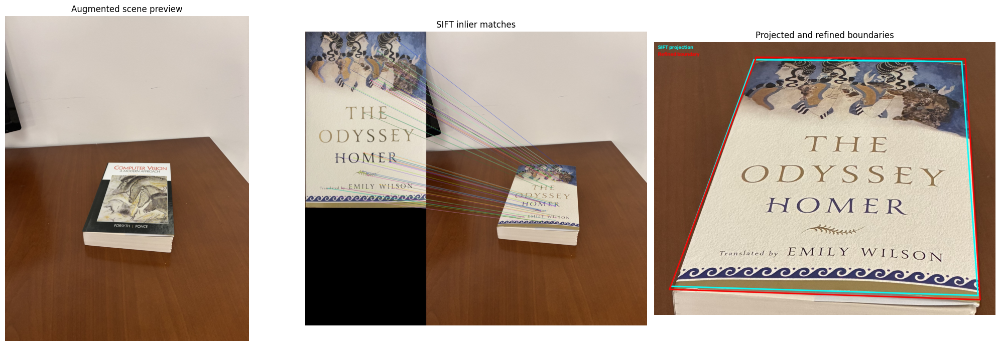

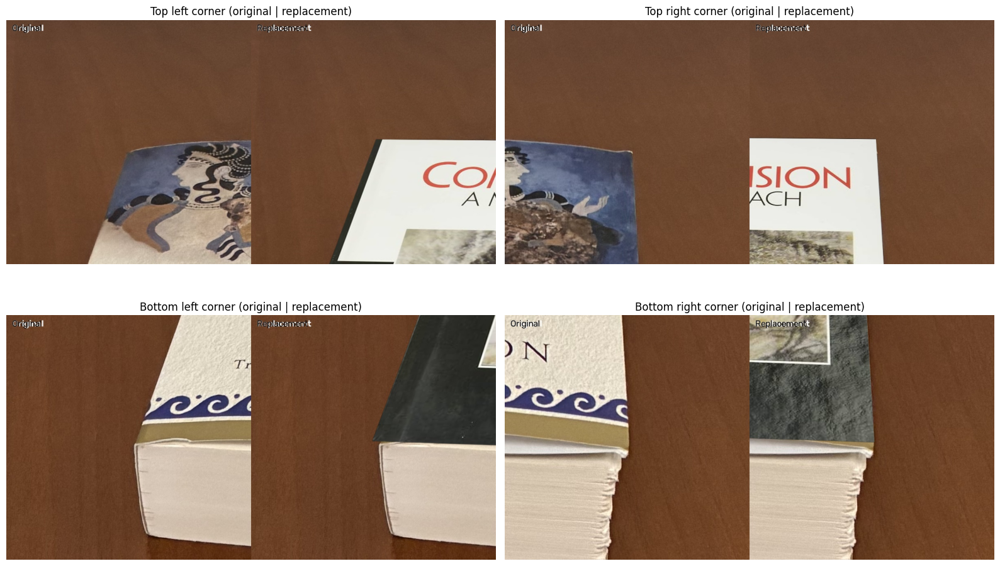

In [14]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
from IPython.display import display


def _read_q2_display(path, max_side=1600):
    image = plt.imread(path)
    scale = min(1.0, max_side / max(image.shape[:2]))
    if scale < 1.0:
        image = cv2.resize(
            image,
            (round(image.shape[1] * scale), round(image.shape[0] * scale)),
            interpolation=cv2.INTER_AREA,
        )
    return image


items = [
    ("Augmented scene preview", Path("outputs/q2/q2_augmented_preview.jpg")),
    ("SIFT inlier matches", Path("outputs/q2/q2_inlier_matches.jpg")),
    ("Projected and refined boundaries", Path("outputs/q2/q2_refinement.jpg")),
]
figure, axes = plt.subplots(1, 3, figsize=(21, 7))
for axis, (title, path) in zip(axes, items, strict=True):
    axis.imshow(_read_q2_display(path))
    axis.set_title(title)
    axis.axis("off")
figure.tight_layout()
display(figure)
plt.close(figure)

corners = [
    ("Top left", Path("outputs/q2/q2_corner_tl.jpg")),
    ("Top right", Path("outputs/q2/q2_corner_tr.jpg")),
    ("Bottom left", Path("outputs/q2/q2_corner_bl.jpg")),
    ("Bottom right", Path("outputs/q2/q2_corner_br.jpg")),
]
figure, axes = plt.subplots(2, 2, figsize=(16, 10))
for axis, (title, path) in zip(axes.flat, corners, strict=True):
    axis.imshow(_read_q2_display(path))
    axis.set_title(f"{title} corner (original | replacement)")
    axis.axis("off")
figure.tight_layout()
display(figure)
plt.close(figure)

### Results

The reference has 4,610 SIFT keypoints and the scene has 1,224. Lowe's test left 233 matches. RANSAC kept 58. Mean inlier reprojection error is 0.99 px, median 0.82 px, so the homography agrees with those inliers to under a pixel.

Refinement pushed the top, right, and bottom sides out by 14, 14, and 19 px. Lab jumps at the new edges are 21.3, 111.2, and 51.7, against 12.9, 4.3, and 11.8 on the original edges. The right side is the obvious one. A jump of 111 against 4.3 is the cover ending and the desk starting. The left side had no stronger edge, so it stays near the SIFT estimate. The line fit still moved it by about 3 px.

Corner crops of the original and the result show the new cover filling the front face out to the desk. The page block and the spine are unchanged.

About 25 percent of the ratio-test matches survived. The cover texture repeats, and the reference scale is far from the book in the photo, so plenty of matches look fine locally and are still wrong. I judge the fit by the 0.99 px reprojection error.

The new art is pasted on with no lighting change. Specular hits on the old cover stay in the scene, and the illumination on the book never moves onto the replacement. Matching the luminance gradient would look more convincing. I left that out.


## Question 3, panoramic stitching

Six unordered photos, two of them warped. I stitch them into one panorama and write each step myself.

A distorted photo has black regions that touch the border. For every image I measure the fraction of border-connected black pixels. Image 1 is 16.4 percent. Image 4 is 10.0 percent. Those two are the distorted ones.

For each distorted image I take the non-black region, fit a line to each side of its contour, and map that quadrilateral back to a rectangle the size of the image. That undoes the warp.

SIFT runs on the corrected images. Every pair gets ratio-test matches and a RANSAC homography. Inlier counts and reprojection errors go into an overlap matrix.

A maximum spanning tree on the inlier counts links each image to its strongest neighbour. I map the image centres into one frame along that tree and sort them by horizontal position. That sort is the left to right order. The middle image is the reference.

Chaining planar homographies across six views stretched the outer images badly. I warp every image onto a cylinder first, focal length 640 px. On the cylinder, neighbours are close to a translation, and I estimate that translation from the matches with a robust fit.

Warped corners, in the centre image's frame, set the bounding box. A translation shifts every coordinate positive. That box is the canvas.

Each image is warped in with a mask of its valid pixels. Overlaps are feathered with a distance transform. Weight grows with distance from that image's border, so seams and leftover brightness steps spread across the overlap. I crop empty border rows.


In [15]:
import time
from pathlib import Path
from typing import Any as Q3Any
from typing import cast

import cv2
import matplotlib.pyplot as plt
import numpy as np

q3_started = time.perf_counter()

DATA = Path("data/q3")
OUT = Path("outputs/q3")


def load_images():
    paths = [DATA / f"Q3_Image_{index}.jpg" for index in range(1, 7)]
    images = [cv2.imread(str(path)) for path in paths]
    if any(image is None for image in images):
        raise FileNotFoundError(f"Could not load all six panorama inputs from {DATA}.")
    return images


def border_black_fraction(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    black = (gray <= 8).astype(np.uint8)
    count, labels = cv2.connectedComponents(black, connectivity=8)
    if count <= 1:
        return 0.0
    border_labels = np.unique(
        np.concatenate((labels[0], labels[-1], labels[:, 0], labels[:, -1]))
    )
    border_labels = border_labels[border_labels != 0]
    return float(np.isin(labels, border_labels).sum() / labels.size)


def order_corners(points):
    points = np.asarray(points, dtype=np.float32)
    center = points.mean(axis=0)
    angles = np.arctan2(points[:, 1] - center[1], points[:, 0] - center[0])
    ordered = points[np.argsort(angles)]
    start = np.argmin(ordered.sum(axis=1))
    ordered = np.roll(ordered, -start, axis=0)
    return ordered


def cross2d_q3(first, second):
    return first[0] * second[1] - first[1] * second[0]


def fit_quad_sides(contour, quad):
    points = contour.reshape(-1, 2).astype(np.float32)
    lines = []
    for index in range(4):
        start = quad[index]
        end = quad[(index + 1) % 4]
        direction = end - start
        length = np.linalg.norm(direction)
        unit = direction / max(length, 1e-6)
        relative = points - start
        projection = relative @ unit
        distance = np.abs(relative[:, 0] * unit[1] - relative[:, 1] * unit[0])
        selected = points[
            (projection >= -3) & (projection <= length + 3) & (distance <= 3)
        ]
        if len(selected) < 8:
            return quad
        fitted = cv2.fitLine(
            selected.reshape(-1, 1, 2), cv2.DIST_WELSCH, 0, 0.01, 0.01
        ).ravel()
        lines.append(
            (
                np.array([fitted[2], fitted[3]], dtype=np.float32),
                np.array([fitted[0], fitted[1]], dtype=np.float32),
            )
        )
    corners = []
    for index in range(4):
        previous_point, previous_direction = lines[(index - 1) % 4]
        point, direction = lines[index]
        denominator = cross2d_q3(previous_direction, direction)
        if abs(denominator) < 1e-5:
            return quad
        scale = cross2d_q3(point - previous_point, direction) / denominator
        corners.append(previous_point + scale * previous_direction)
    corners = np.asarray(corners, dtype=np.float32)
    if not cv2.isContourConvex(np.round(corners).astype(np.int32)):
        return quad
    if max(np.ptp(corners[:, 0]), np.ptp(corners[:, 1])) > 1.5 * max(
        np.ptp(quad[:, 0]), np.ptp(quad[:, 1])
    ):
        return quad
    return corners


def find_valid_quad(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    valid = (gray > 8).astype(np.uint8) * 255
    kernel = np.ones((3, 3), np.uint8)
    valid = cv2.morphologyEx(valid, cv2.MORPH_OPEN, kernel)
    valid = cv2.morphologyEx(valid, cv2.MORPH_CLOSE, kernel, iterations=2)
    contours, _ = cv2.findContours(valid, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        raise RuntimeError("No valid-content contour found in distorted image.")
    contour = max(contours, key=cv2.contourArea)
    perimeter = cv2.arcLength(contour, True)
    quad = None
    for fraction in np.arange(0.004, 0.081, 0.002):
        approximation = cv2.approxPolyDP(contour, fraction * perimeter, True)
        if len(approximation) == 4:
            quad = approximation[:, 0, :].astype(np.float32)
            break
    if quad is None:
        quad = cv2.boxPoints(cv2.minAreaRect(contour))
    quad = order_corners(quad)
    h, w = image.shape[:2]
    clipped = (
        np.any(quad[:, 0] <= 1)
        or np.any(quad[:, 0] >= w - 2)
        or np.any(quad[:, 1] <= 1)
        or np.any(quad[:, 1] >= h - 2)
    )
    if clipped:
        quad = fit_quad_sides(contour, quad)
    return quad


def correct_distortions(images):
    corrected = []
    masks = []
    records = []
    for index, image in enumerate(images):
        fraction = border_black_fraction(image)
        is_distorted = fraction > 0.015
        h, w = image.shape[:2]
        valid_mask = np.ones((h, w), dtype=np.uint8) * 255
        if is_distorted:
            quad = find_valid_quad(image)
            destination = np.asarray(
                [[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]],
                dtype=np.float32,
            )
            transform = cv2.getPerspectiveTransform(quad, destination)
            warped = cv2.warpPerspective(
                image,
                transform,
                (w, h),
                flags=cv2.INTER_LINEAR,
                borderMode=cv2.BORDER_CONSTANT,
            )
        else:
            quad = None
            transform = np.eye(3, dtype=np.float64)
            warped = image.copy()
        corrected.append(warped)
        masks.append(valid_mask)
        records.append(
            {
                "index": index,
                "black_fraction": fraction,
                "distorted": is_distorted,
                "quad": quad,
                "transform": transform,
            }
        )
    return corrected, masks, records


def extract_features(images):
    sift = cast(Q3Any, cv2).SIFT_create(nfeatures=5000)
    features = []
    for image in images:
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        features.append(sift.detectAndCompute(gray, None))
    return features


def estimate_pair(feature_i, feature_j):
    keypoints_i, descriptors_i = feature_i
    keypoints_j, descriptors_j = feature_j
    if descriptors_i is None or descriptors_j is None:
        return None, 0, 0
    matches = cv2.BFMatcher(cv2.NORM_L2).knnMatch(descriptors_i, descriptors_j, k=2)
    good = [a for a, b in matches if a.distance < 0.75 * b.distance]
    if len(good) < 4:
        return None, 0, 0
    points_i = np.asarray([keypoints_i[m.queryIdx].pt for m in good], dtype=np.float32)
    points_j = np.asarray([keypoints_j[m.trainIdx].pt for m in good], dtype=np.float32)
    homography, inlier_mask = cv2.findHomography(
        points_i, points_j, cv2.USAC_MAGSAC, 3.0, maxIters=10000, confidence=0.999
    )
    if homography is None or inlier_mask is None:
        return None, 0, 0
    return homography, int(inlier_mask.sum()), len(good)


def pairwise_homographies(features):
    count = len(features)
    homographies = {}
    inliers = np.zeros((count, count), dtype=np.int32)
    ratios = np.zeros((count, count), dtype=np.float32)
    for i in range(count):
        for j in range(i + 1, count):
            homography, n_inliers, n_good = estimate_pair(features[i], features[j])
            if homography is None:
                continue
            homographies[(i, j)] = homography
            inliers[i, j] = inliers[j, i] = n_inliers
            ratios[i, j] = ratios[j, i] = n_inliers / max(n_good, 1)
    return homographies, inliers, ratios


def cylindrical_warp(image, mask, focal_length=640.0):
    h, w = image.shape[:2]
    center_x, center_y = (w - 1) / 2.0, (h - 1) / 2.0
    destination_x, destination_y = np.meshgrid(
        np.arange(w, dtype=np.float32), np.arange(h, dtype=np.float32)
    )
    angle = (destination_x - center_x) / focal_length
    source_x = focal_length * np.tan(angle) + center_x
    source_y = (destination_y - center_y) * np.sqrt(
        (source_x - center_x) ** 2 + focal_length**2
    ) / focal_length + center_y
    map_x = source_x.astype(np.float32)
    map_y = source_y.astype(np.float32)
    warped_image = cv2.remap(
        image, map_x, map_y, cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT
    )
    warped_mask = cv2.remap(
        mask, map_x, map_y, cv2.INTER_NEAREST, borderMode=cv2.BORDER_CONSTANT
    )
    return warped_image, warped_mask


def pairwise_cylindrical_translations(features):
    count = len(features)
    translations = {}
    inliers = np.zeros((count, count), dtype=np.int32)
    ratios = np.zeros((count, count), dtype=np.float32)
    errors = {}
    for i in range(count):
        for j in range(i + 1, count):
            keypoints_i, descriptors_i = features[i]
            keypoints_j, descriptors_j = features[j]
            if descriptors_i is None or descriptors_j is None:
                errors[(i, j)] = np.empty(0, dtype=np.float32)
                continue
            matches = cv2.BFMatcher(cv2.NORM_L2).knnMatch(
                descriptors_i, descriptors_j, k=2
            )
            good = [a for a, b in matches if a.distance < 0.75 * b.distance]
            if len(good) < 4:
                errors[(i, j)] = np.empty(0, dtype=np.float32)
                continue
            points_i = np.asarray(
                [keypoints_i[m.queryIdx].pt for m in good], dtype=np.float32
            )
            points_j = np.asarray(
                [keypoints_j[m.trainIdx].pt for m in good], dtype=np.float32
            )
            homography, inlier_mask = cv2.findHomography(
                points_i,
                points_j,
                cv2.USAC_MAGSAC,
                3.0,
                maxIters=10000,
                confidence=0.999,
            )
            if homography is None or inlier_mask is None:
                errors[(i, j)] = np.empty(0, dtype=np.float32)
                continue
            inlier_mask = inlier_mask.ravel().astype(bool)
            projected = cv2.perspectiveTransform(
                points_i[inlier_mask, None, :], homography
            )[:, 0]
            pair_errors = np.linalg.norm(projected - points_j[inlier_mask], axis=1)
            delta = np.median(points_j[inlier_mask] - points_i[inlier_mask], axis=0)
            translations[(i, j)] = np.array(
                [[1.0, 0.0, delta[0]], [0.0, 1.0, delta[1]], [0.0, 0.0, 1.0]],
                dtype=np.float64,
            )
            inliers[i, j] = inliers[j, i] = int(inlier_mask.sum())
            ratio = inlier_mask.sum() / max(len(good), 1)
            ratios[i, j] = ratios[j, i] = ratio
            errors[(i, j)] = pair_errors
    return translations, inliers, ratios, errors


def maximum_spanning_tree(homographies, inliers, ratios):
    count = inliers.shape[0]
    accepted = {
        edge
        for edge, homography in homographies.items()
        if inliers[edge] >= 30 and ratios[edge] >= 0.20
    }

    def grow_tree(edges):
        tree = []
        included = {0}
        while len(included) < count:
            options = []
            for i, j in edges:
                if (i in included) != (j in included):
                    options.append((int(inliers[i, j]), i, j))
            if not options:
                return None
            weight, i, j = max(options)
            tree.append((i, j, weight))
            included.add(j if i in included else i)
        return tree

    tree = grow_tree(accepted)
    if tree is None:
        fallback = {
            edge for edge in homographies if inliers[edge] >= 8 and ratios[edge] >= 0.10
        }
        tree = grow_tree(fallback)
    if tree is None:
        raise RuntimeError(
            "The pairwise overlap graph is disconnected; cannot build a panorama tree."
        )
    return tree


def tree_maps_to_root(tree, homographies, count, root):
    adjacency = {index: {} for index in range(count)}
    for i, j, _ in tree:
        h_i_j = homographies[(min(i, j), max(i, j))]
        if i > j:
            h_i_j = np.linalg.inv(h_i_j)
        adjacency[i][j] = np.linalg.inv(h_i_j)
        adjacency[j][i] = h_i_j
    transforms = {root: np.eye(3, dtype=np.float64)}
    stack = [root]
    while stack:
        parent = stack.pop()
        for child, h_child_parent in adjacency[parent].items():
            if child in transforms:
                continue
            transforms[child] = transforms[parent] @ h_child_parent
            stack.append(child)
    return transforms


def mapped_center(transform, shape):
    h, w = shape[:2]
    point = np.asarray([[[(w - 1) / 2, (h - 1) / 2]]], dtype=np.float32)
    return cv2.perspectiveTransform(point, transform)[0, 0]


def projectivity_measure(homography, image_shape):
    matrix = homography / homography[2, 2]
    return float(np.linalg.norm(matrix[2, :2]) * np.hypot(*image_shape[:2]))


def stitch(corrected, masks, homographies, inliers, ratios, tree):
    count = len(corrected)
    root_maps = tree_maps_to_root(tree, homographies, count, root=0)
    positions = {
        index: mapped_center(root_maps[index], corrected[index].shape)
        for index in range(count)
    }
    order = sorted(range(count), key=lambda index: positions[index][0])
    reference = order[len(order) // 2]
    root_to_reference = np.linalg.inv(root_maps[reference])
    image_to_reference = {
        index: root_to_reference @ root_maps[index] for index in range(count)
    }

    corners = np.asarray(
        [
            [0, 0],
            [corrected[0].shape[1], 0],
            [corrected[0].shape[1], corrected[0].shape[0]],
            [0, corrected[0].shape[0]],
        ],
        dtype=np.float32,
    )
    all_corners = [
        cv2.perspectiveTransform(corners[None, :, :], image_to_reference[index])[0]
        for index in range(count)
    ]
    all_corners = np.concatenate(all_corners, axis=0)
    minimum = np.floor(all_corners.min(axis=0)).astype(int)
    maximum = np.ceil(all_corners.max(axis=0)).astype(int)
    canvas_width, canvas_height = (maximum - minimum).tolist()
    if (
        canvas_width <= 0
        or canvas_height <= 0
        or canvas_width * canvas_height > 100_000_000
    ):
        raise RuntimeError(
            f"Unsafe panorama canvas size: {canvas_width}x{canvas_height}."
        )
    translation = np.array(
        [[1, 0, -minimum[0]], [0, 1, -minimum[1]], [0, 0, 1]], dtype=np.float64
    )
    warped_images = []
    warped_masks = []
    for image, mask, transform in zip(
        corrected, masks, image_to_reference.values(), strict=True
    ):
        total = translation @ transform
        warped_images.append(
            cv2.warpPerspective(
                image,
                total,
                (canvas_width, canvas_height),
                flags=cv2.INTER_LINEAR,
                borderMode=cv2.BORDER_CONSTANT,
            )
        )
        warped_masks.append(
            cv2.warpPerspective(
                mask,
                total,
                (canvas_width, canvas_height),
                flags=cv2.INTER_NEAREST,
                borderMode=cv2.BORDER_CONSTANT,
            )
        )

    weighted_sum = np.zeros((canvas_height, canvas_width, 3), dtype=np.float32)
    weight_sum = np.zeros((canvas_height, canvas_width), dtype=np.float32)
    naive = np.zeros((canvas_height, canvas_width, 3), dtype=np.uint8)
    for index in order:
        mask = (warped_masks[index] > 0).astype(np.uint8)
        distance = cv2.distanceTransform(mask, cv2.DIST_L2, 3)
        weights = distance * mask
        weighted_sum += warped_images[index].astype(np.float32) * weights[:, :, None]
        weight_sum += weights
        naive[mask > 0] = warped_images[index][mask > 0]
    blended = (
        np.divide(
            weighted_sum,
            np.maximum(weight_sum[:, :, None], 1e-6),
            out=np.zeros_like(weighted_sum),
            where=weight_sum[:, :, None] > 0,
        )
        .clip(0, 255)
        .astype(np.uint8)
    )
    union = (weight_sum > 0).astype(np.uint8)
    points = cv2.findNonZero(union)
    x, y, width, height = cv2.boundingRect(points)
    crop = np.s_[y : y + height, x : x + width]
    return {
        "blended": blended[crop],
        "naive": naive[crop],
        "warped_images": [image[crop] for image in warped_images],
        "warped_masks": [mask[crop] for mask in warped_masks],
        "order": order,
        "reference": reference,
        "positions": positions,
        "canvas_size": (canvas_width, canvas_height),
        "crop_bounds": (x, y, width, height),
        "tree": tree,
    }


def save_jpeg(path, image, max_side=1800, quality=94):
    scale = min(1.0, max_side / max(image.shape[:2]))
    if scale < 1.0:
        image = cv2.resize(
            image,
            (round(image.shape[1] * scale), round(image.shape[0] * scale)),
            interpolation=cv2.INTER_AREA,
        )
    cv2.imwrite(str(path), image, [cv2.IMWRITE_JPEG_QUALITY, quality])


def save_correction_figure(images, corrected, records):
    figure, axes = plt.subplots(6, 2, figsize=(12, 14), dpi=110)
    axes[0, 0].set_title("Input")
    axes[0, 1].set_title("Corrected")
    for index, (before, after, record) in enumerate(
        zip(images, corrected, records, strict=True)
    ):
        axes[index, 0].imshow(cv2.cvtColor(before, cv2.COLOR_BGR2RGB))
        axes[index, 1].imshow(cv2.cvtColor(after, cv2.COLOR_BGR2RGB))
        axes[index, 0].set_ylabel(
            f"Image {index + 1}\nborder black={record['black_fraction']:.3f}"
        )
        for axis in axes[index]:
            axis.set_xticks([])
            axis.set_yticks([])
    figure.tight_layout()
    figure.savefig(OUT / "q3_correction_before_after.png", bbox_inches="tight")
    plt.close(figure)


def save_heatmap(inliers):
    figure, axis = plt.subplots(figsize=(7, 6), dpi=150)
    image = axis.imshow(inliers, cmap="magma")
    axis.set_xticks(range(6), labels=[str(index) for index in range(1, 7)])
    axis.set_yticks(range(6), labels=[str(index) for index in range(1, 7)])
    axis.set_xlabel("Image")
    axis.set_ylabel("Image")
    axis.set_title("Pairwise SIFT/RANSAC inlier counts")
    for row in range(6):
        for col in range(6):
            axis.text(
                col,
                row,
                str(inliers[row, col]),
                ha="center",
                va="center",
                color="white" if inliers[row, col] < inliers.max() * 0.65 else "black",
                fontsize=8,
            )
    figure.colorbar(image, ax=axis, shrink=0.8, label="Inliers")
    figure.tight_layout()
    figure.savefig(OUT / "q3_overlap_heatmap.png", bbox_inches="tight")
    plt.close(figure)


def save_seam_comparison(result):
    i, j, _ = max(result["tree"], key=lambda edge: edge[2])
    overlap = (
        (result["warped_masks"][i] > 0) & (result["warped_masks"][j] > 0)
    ).astype(np.uint8)
    points = cv2.findNonZero(overlap)
    if points is None:
        return
    x, y, width, height = cv2.boundingRect(points)
    center_x, center_y = x + width // 2, y + height // 2
    crop_width, crop_height = min(width, 700), min(height, 500)
    x0 = max(0, min(center_x - crop_width // 2, overlap.shape[1] - crop_width))
    y0 = max(0, min(center_y - crop_height // 2, overlap.shape[0] - crop_height))
    region = np.s_[y0 : y0 + crop_height, x0 : x0 + crop_width]
    naive_crop = result["naive"][region].copy()
    blended_crop = result["blended"][region].copy()
    cv2.putText(
        naive_crop,
        "Naive overlay",
        (14, 28),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (255, 255, 255),
        2,
        cv2.LINE_AA,
    )
    cv2.putText(
        blended_crop,
        "Feather blend",
        (14, 28),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (255, 255, 255),
        2,
        cv2.LINE_AA,
    )
    cv2.imwrite(
        str(OUT / "q3_naive_vs_blended_seam.png"), np.hstack((naive_crop, blended_crop))
    )


def main():
    OUT.mkdir(parents=True, exist_ok=True)
    images = load_images()
    corrected, masks, records = correct_distortions(images)
    save_correction_figure(images, corrected, records)

    original_features = extract_features(images)
    corrected_features = extract_features(corrected)
    homographies, inliers, ratios = pairwise_homographies(corrected_features)
    homography_tree = maximum_spanning_tree(homographies, inliers, ratios)
    homography_result = stitch(
        corrected, masks, homographies, inliers, ratios, homography_tree
    )
    save_jpeg(OUT / "q3_panorama_homography_preview.jpg", homography_result["blended"])

    cylindrical_images, cylindrical_masks = zip(
        *(
            cylindrical_warp(image, mask)
            for image, mask in zip(corrected, masks, strict=True)
        ),
        strict=True,
    )
    cylindrical_features = extract_features(cylindrical_images)
    translations, cylindrical_inliers, cylindrical_ratios, cylindrical_errors = (
        pairwise_cylindrical_translations(cylindrical_features)
    )
    cylindrical_tree = maximum_spanning_tree(
        translations, cylindrical_inliers, cylindrical_ratios
    )
    result = stitch(
        list(cylindrical_images),
        list(cylindrical_masks),
        translations,
        cylindrical_inliers,
        cylindrical_ratios,
        cylindrical_tree,
    )
    save_heatmap(cylindrical_inliers)
    save_seam_comparison(result)
    cv2.imwrite(str(OUT / "q3_panorama_full.png"), result["blended"])
    save_jpeg(OUT / "q3_panorama_preview.jpg", result["blended"])

    print("Detected distorted images (automatic near-black border test):")
    for record in records:
        status = "corrected" if record["distorted"] else "unchanged"
        print(
            f"  Image {record['index'] + 1}: border-connected black fraction="
            f"{record['black_fraction']:.4f}, {status}"
        )
        if record["quad"] is not None:
            print(f"    valid-content quad: {np.round(record['quad'], 1).tolist()}")
    print("Pairwise inlier counts (rows/columns are images 1–6):")
    print(inliers)
    print("Cylindrical-projection pairwise inlier counts:")
    print(cylindrical_inliers)
    print("Cylindrical pairwise inlier reprojection errors:")
    for (i, j), pair_errors in sorted(cylindrical_errors.items()):
        if cylindrical_inliers[i, j]:
            print(
                f"  {i + 1}-{j + 1}: {cylindrical_inliers[i, j]} inliers, "
                f"mean={pair_errors.mean():.3f}px, "
                f"median={np.median(pair_errors):.3f}px"
            )
    print("Cylindrical maximum spanning tree:")
    for i, j, weight in cylindrical_tree:
        print(f"  {i + 1}-{j + 1}: {weight} inliers")
    print(
        "Left-to-right order: "
        + " -> ".join(str(index + 1) for index in result["order"])
    )
    print(f"Reference image: {result['reference'] + 1}")
    print(
        f"Canvas size before empty-border crop: "
        f"{result['canvas_size'][0]}x{result['canvas_size'][1]}"
    )
    print(
        f"Panorama size after empty-border crop: "
        f"{result['blended'].shape[1]}x{result['blended'].shape[0]}"
    )
    print(
        f"Homography panorama size: "
        f"{homography_result['blended'].shape[1]}x{homography_result['blended'].shape[0]}"
    )
    print(
        "Correction sanity (dimensionless homography projectivity term on tree edges):"
    )
    sanity_edges = [
        edge
        for edge in homography_tree
        if records[edge[0]]["distorted"] or records[edge[1]]["distorted"]
    ]
    for i, j, _ in sanity_edges:
        key = (min(i, j), max(i, j))
        corrected_value = projectivity_measure(homographies[key], corrected[i].shape)
        raw_h, raw_inliers, _ = estimate_pair(
            original_features[i], original_features[j]
        )
        if raw_h is None:
            print(
                f"  {i + 1}-{j + 1}: corrected={corrected_value:.5f}; "
                "raw comparison unavailable"
            )
        else:
            raw_value = projectivity_measure(raw_h, images[i].shape)
            print(
                f"  {i + 1}-{j + 1}: raw={raw_value:.5f} ({raw_inliers} inliers), "
                f"corrected={corrected_value:.5f} ({inliers[key]} inliers)"
            )
    print(f"Output directory: {OUT}")


main()

print(f"Q3 solve runtime: {time.perf_counter() - q3_started:.2f} s")

Detected distorted images (automatic near-black border test):
  Image 1: border-connected black fraction=0.1637, corrected
    valid-content quad: [[77.80000305175781, 25.100000381469727], [609.9000244140625, 3.0], [638.7999877929688, 438.0], [17.700000762939453, 478.8999938964844]]
  Image 2: border-connected black fraction=0.0000, unchanged
  Image 3: border-connected black fraction=0.0000, unchanged
  Image 4: border-connected black fraction=0.0999, corrected
    valid-content quad: [[0.5, 70.5999984741211], [591.2999877929688, -0.30000001192092896], [639.2999877929688, 409.0], [47.70000076293945, 478.5]]
  Image 5: border-connected black fraction=0.0000, unchanged
  Image 6: border-connected black fraction=0.0000, unchanged
Pairwise inlier counts (rows/columns are images 1–6):
[[  0   4 204  33   0 150]
 [  4   0   0  73  65   0]
 [204   0   0   0   0   0]
 [ 33  73   0   0   5 480]
 [  0  65   0   5   0   0]
 [150   0   0 480   0   0]]
Cylindrical-projection pairwise inlier counts

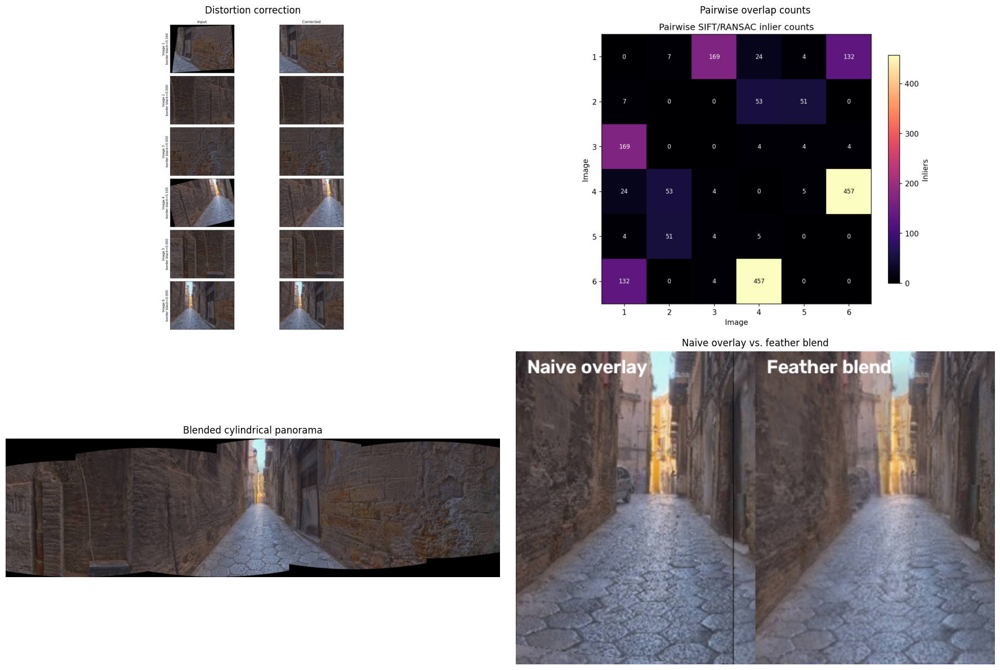

In [16]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
from IPython.display import display


def _read_q3_display(path, max_side=1600):
    image = plt.imread(path)
    scale = min(1.0, max_side / max(image.shape[:2]))
    if scale < 1.0:
        image = cv2.resize(
            image,
            (round(image.shape[1] * scale), round(image.shape[0] * scale)),
            interpolation=cv2.INTER_AREA,
        )
    return image


items = [
    ("Distortion correction", Path("outputs/q3/q3_correction_before_after.png")),
    ("Pairwise overlap counts", Path("outputs/q3/q3_overlap_heatmap.png")),
    ("Blended cylindrical panorama", Path("outputs/q3/q3_panorama_full.png")),
    (
        "Naive overlay vs. feather blend",
        Path("outputs/q3/q3_naive_vs_blended_seam.png"),
    ),
]
figure, axes = plt.subplots(2, 2, figsize=(18, 12))
for axis, (title, path) in zip(axes.flat, items, strict=True):
    axis.imshow(_read_q3_display(path))
    axis.set_title(title)
    axis.axis("off")
figure.tight_layout()
display(figure)
plt.close(figure)

### Results

Images 1 and 4 were flagged as distorted and rectified before matching. The before and after figure is in the cell above.

Left to right the order is 5, 2, 4, 6, 1, 3. Image 6 is the centre, and it is the reference.

Cylindrical inliers on the strong pairs are 457 for 4 with 6, 169 for 1 with 3, 132 for 1 with 6, 53 for 2 with 4, and 51 for 2 with 5. Those are the neighbours in the order above. Every other pair has at most 24 inliers. 457 against 24 is not a close call.

The canvas is 2079 by 572 px before the empty border is cropped, and 2033 by 571 px after.

A plain overlay still has hard seams and sudden brightness steps. Feathering takes both out.

Black strips remain on the top and bottom, on rows no photo covers. Cropping them off would cut real content, so they stay. Parallax shows where the scene is close to the camera. The cylinder assumes it is far.


## Question 4, segmentation from clicks

`clicks.json` has one polyline of clicks per animal. Those clicks are definite foreground. I save each instance as a transparent RGBA cut-out.

I resize so the long side is 900 px, and I upsample the mask at the end.

SLIC builds about 2,500 superpixels. Each descriptor holds the mean and standard deviation of Lab colour, Gabor energy at 2 scales and 4 orientations, and a uniform LBP histogram. The animals are camouflaged. Bark and rock match the coat in colour, so Gabor energy and LBP are what separate the animal.

Foreground seeds are the superpixels on the polyline through the clicks. Background seeds are superpixels farther than 30 percent of the click extent outside the click bounding box. The box comes from the clicks.

`d_fg` is the k-NN descriptor distance to the foreground seeds, and `d_bg` is the distance to the background seeds. The prior is `p = d_bg / (d_fg + d_bg)`.

GrabCut starts from that prior. `p > 0.55` is probable foreground, and the rest is probable background. Background seeds are definite background, and a small disk around each click is definite foreground. GrabCut runs on a Retinex image, the log of the pixels minus the log of a wide Gaussian blur. That blur term flattens shadows and sun patches.

I keep connected components that contain a click, fill holes, close the mask, and scale it back to the original size.

`<instance>.png` stores the original RGB values, with alpha 255 inside the mask and 0 outside. A tight crop and the binary mask are saved beside it.


lizard_1        Q4_Image_1.jpg: area 3.0% of image, bbox x[721,1157] y[296,806], all 3 clicks inside mask
snow_leopard_1  Q4_Image_2.jpg: area 16.9% of image, bbox x[598,1767] y[321,1113], all 3 clicks inside mask
owl_1           Q4_Image_3.jpg: area 4.5% of image, bbox x[805,1184] y[1167,1629], all 3 clicks inside mask
Q4 solve runtime: 23.18 s


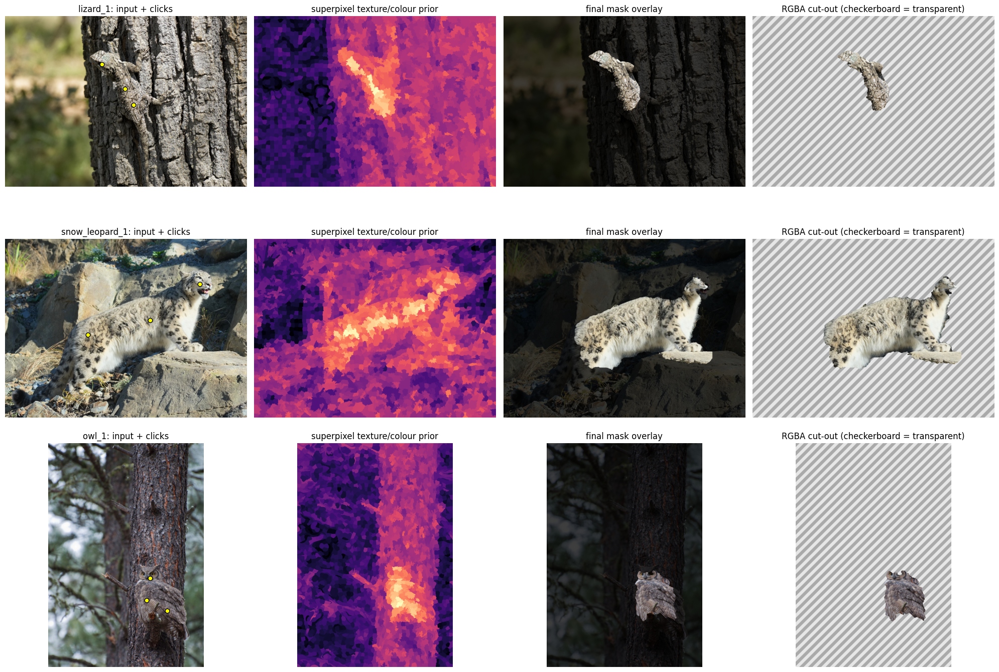

In [8]:
import json
import time
from pathlib import Path
from typing import Any as Q4Any
from typing import cast

import cv2
import matplotlib.pyplot as plt
import numpy as np
from scipy import ndimage as ndi
from skimage.feature import local_binary_pattern
from skimage.segmentation import slic

q4_started = time.perf_counter()

DATA = Path("data/q4")
OUT = Path("outputs/q4")
OUT.mkdir(parents=True, exist_ok=True)
WORK_SIZE = 900
BG_MARGIN = 0.3
PRIOR_THR = 0.55
RETINEX_SIGMA = 40


def texture_color_features(img):
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB).astype(np.float32) / 255
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float32) / 255
    chans = [lab[..., i] for i in range(3)]
    for ksize, sigma in [(15, 3), (31, 6)]:
        for theta in np.arange(4) * np.pi / 4:
            kern = cv2.getGaborKernel((ksize, ksize), sigma, theta, sigma * 2, 0.5, 0)
            kern -= kern.mean()
            resp = np.abs(cv2.filter2D(gray, cv2.CV_32F, kern))
            chans.append(cv2.GaussianBlur(resp, (0, 0), sigma))
    lbp = local_binary_pattern((gray * 255).astype(np.uint8), 8, 1.5, "uniform")
    return np.stack(chans, -1), lbp


def superpixel_descriptors(img, n_segments=2500):
    feats, lbp = texture_color_features(img)
    sp = slic(
        cv2.cvtColor(img, cv2.COLOR_BGR2RGB),
        n_segments=n_segments,
        compactness=10,
        start_label=0,
    )
    n = sp.max() + 1
    flat = sp.ravel()
    count = np.bincount(flat, minlength=n).astype(float)

    def mean(values):
        return np.bincount(flat, values.ravel(), n) / count

    desc = [mean(feats[..., c]) for c in range(feats.shape[-1])]
    desc += [
        np.sqrt(np.maximum(mean(feats[..., c] ** 2) - desc[c] ** 2, 0))
        for c in range(3)
    ]
    desc += [mean((lbp == b).astype(float)) for b in range(10)]
    desc = np.stack(desc, 1)
    desc = (desc - desc.mean(0)) / (desc.std(0) + 1e-6)
    yy, xx = np.mgrid[: img.shape[0], : img.shape[1]]
    centers = np.c_[mean(xx), mean(yy)]
    return sp, desc, centers


def knn_dist(query, ref, k=3):
    d2 = ((query[:, None, :] - ref[None, :, :]) ** 2).sum(-1)
    return np.sqrt(np.sort(d2, 1)[:, :k].mean(1))


def retinex(img, sigma):
    f = img.astype(np.float32) + 1
    lum = cv2.GaussianBlur(f.mean(-1), (0, 0), sigma)[..., None]
    r = np.log(f) - np.log(lum)
    lo, hi = np.percentile(r, 1), np.percentile(r, 99)
    return (np.clip((r - lo) / (hi - lo), 0, 1) * 255).astype(np.uint8)


def segment(img, clicks):
    h, w = img.shape[:2]
    s = WORK_SIZE / max(h, w)
    small = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    pts = np.round(np.asarray(clicks) * s).astype(int)
    (x0, y0), (x1, y1) = pts.min(0), pts.max(0)
    extent = max(x1 - x0, y1 - y0)

    sp, desc, centers = superpixel_descriptors(small)
    path = np.zeros(small.shape[:2], np.uint8)
    for a, b in zip(pts[:-1], pts[1:], strict=True):
        cv2.line(path, tuple(map(int, a)), tuple(map(int, b)), 1, 3)
    fg_sp = np.unique(sp[path > 0])
    m = BG_MARGIN * extent
    cx, cy = centers[:, 0], centers[:, 1]
    bg_sp = np.nonzero((cx < x0 - m) | (cx > x1 + m) | (cy < y0 - m) | (cy > y1 + m))[0]
    d_fg, d_bg = knn_dist(desc, desc[fg_sp]), knn_dist(desc, desc[bg_sp])
    prior = (d_bg / (d_fg + d_bg))[sp]

    gc_mask = np.where(prior > PRIOR_THR, cv2.GC_PR_FGD, cv2.GC_PR_BGD).astype(np.uint8)
    gc_mask[np.isin(sp, bg_sp)] = cv2.GC_BGD
    for p in pts:
        cv2.circle(gc_mask, tuple(map(int, p)), int(0.02 * extent) + 3, cv2.GC_FGD, -1)
    bgd, fgd = np.zeros((1, 65)), np.zeros((1, 65))
    cast(Q4Any, cv2).grabCut(
        retinex(small, RETINEX_SIGMA), gc_mask, None, bgd, fgd, 6, cv2.GC_INIT_WITH_MASK
    )
    fg = np.isin(gc_mask, [cv2.GC_FGD, cv2.GC_PR_FGD])

    lab, _ = ndi.label(fg)
    keep = np.unique(lab[pts[:, 1], pts[:, 0]])
    fg = ndi.binary_fill_holes(np.isin(lab, keep[keep > 0]))
    fg = cv2.morphologyEx(
        fg.astype(np.uint8),
        cv2.MORPH_CLOSE,
        cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)),
    )

    soft = cv2.resize(fg.astype(np.float32), (w, h), interpolation=cv2.INTER_LINEAR)
    soft = cv2.GaussianBlur(soft, (0, 0), 1.0 / s)
    full = (soft > 0.5).astype(np.uint8)
    for x, y in np.asarray(clicks):
        assert full[y, x], "click not in mask"
    return full, cv2.resize(prior.astype(np.float32), (w, h))


clicks_all = json.loads((DATA / "clicks.json").read_text())
results = []
for fname, objects in clicks_all.items():
    img = cast(np.ndarray, cv2.imread(str(DATA / fname)))
    for obj, info in objects.items():
        mask, prior = segment(img, info["clicks"])
        rgba = cv2.cvtColor(img, cv2.COLOR_BGR2BGRA)
        rgba[..., 3] = mask * 255
        ys, xs = np.nonzero(mask)
        cv2.imwrite(str(OUT / f"{obj}.png"), rgba)
        cv2.imwrite(
            str(OUT / f"{obj}_cropped.png"),
            rgba[ys.min() : ys.max() + 1, xs.min() : xs.max() + 1],
        )
        cv2.imwrite(str(OUT / f"{obj}_mask.png"), mask * 255)
        print(
            f"{obj:15s} {fname}: area {mask.sum() / mask.size:.1%} of image, bbox "
            f"x[{xs.min()},{xs.max()}] y[{ys.min()},{ys.max()}], "
            f"all {len(info['clicks'])} clicks inside mask"
        )
        results.append((obj, img, info["clicks"], prior, mask, rgba))

fig, ax = plt.subplots(len(results), 4, figsize=(20, 4.6 * len(results)))
for row, (obj, img, clicks, prior, mask, rgba) in enumerate(results):
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    ax[row, 0].imshow(rgb)
    ax[row, 0].scatter(*np.asarray(clicks).T, c="yellow", s=40, edgecolors="k")
    ax[row, 0].set_title(f"{obj}: input + clicks")
    ax[row, 1].imshow(prior, cmap="magma")
    ax[row, 1].set_title("superpixel texture/colour prior")
    over = rgb.copy()
    over[mask == 0] = (over[mask == 0] * 0.25).astype(np.uint8)
    ax[row, 2].imshow(over)
    ax[row, 2].set_title("final mask overlay")
    checker = (np.indices(mask.shape).sum(0) // 40 % 2)[..., None] * 60 + 170
    comp = rgba[..., :3][..., ::-1] * (mask[..., None]) + checker * (
        1 - mask[..., None]
    )
    ax[row, 3].imshow(comp.astype(np.uint8))
    ax[row, 3].set_title("RGBA cut-out (checkerboard = transparent)")
    for a in ax[row]:
        a.axis("off")
plt.tight_layout()
plt.savefig(OUT / "summary.jpg", dpi=70)

print(f"Q4 solve runtime: {time.perf_counter() - q4_started:.2f} s")

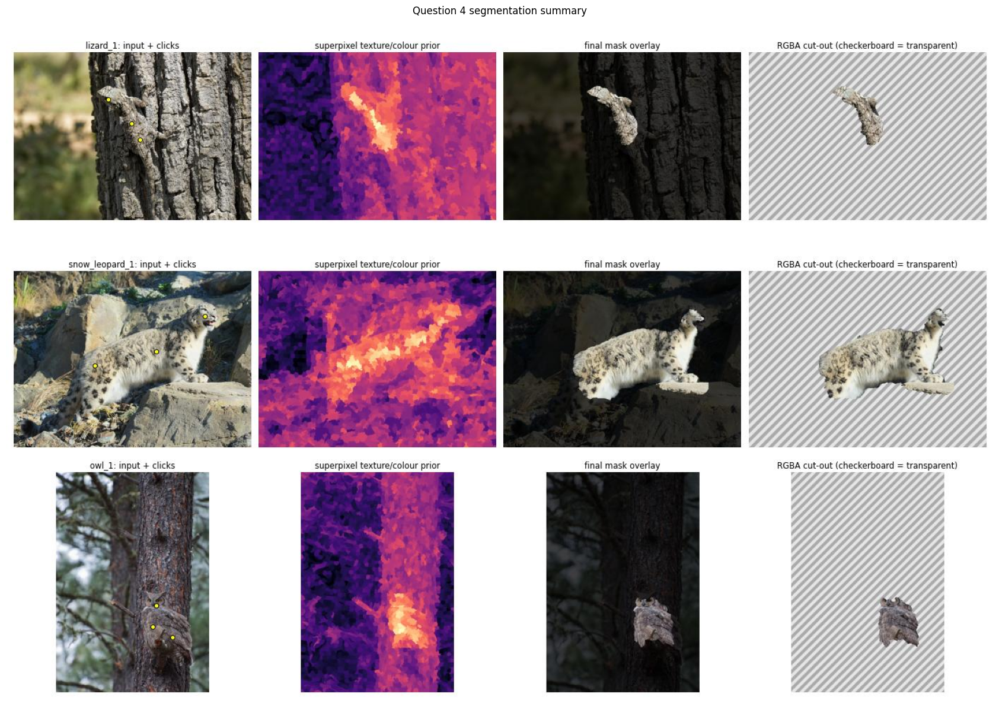

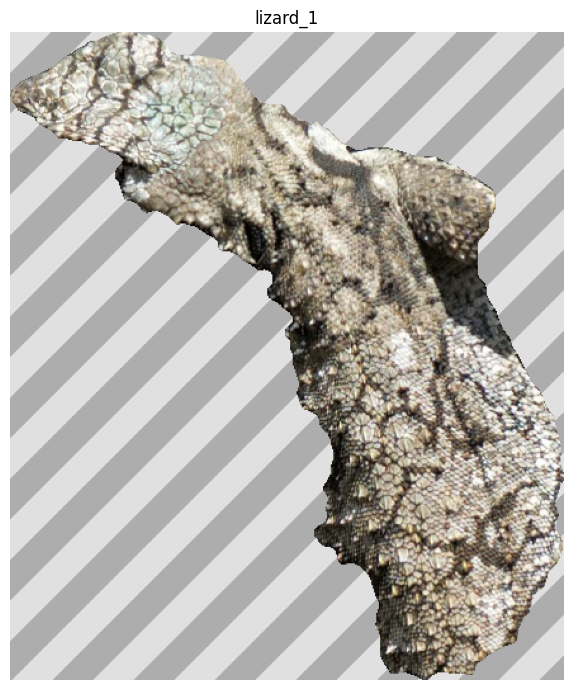

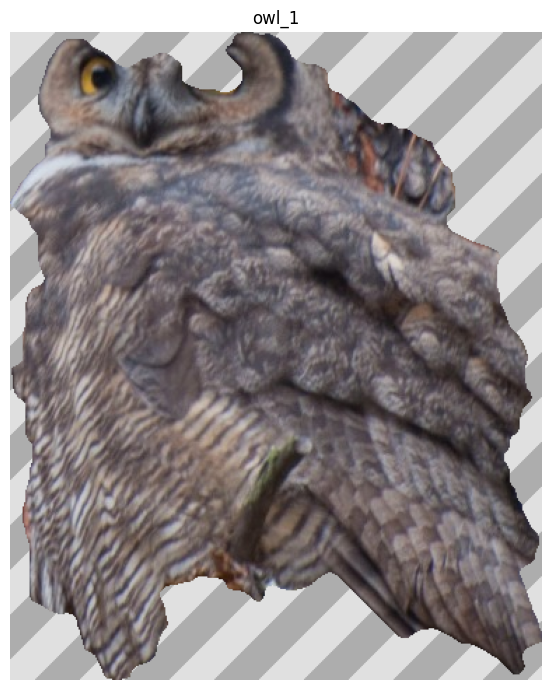

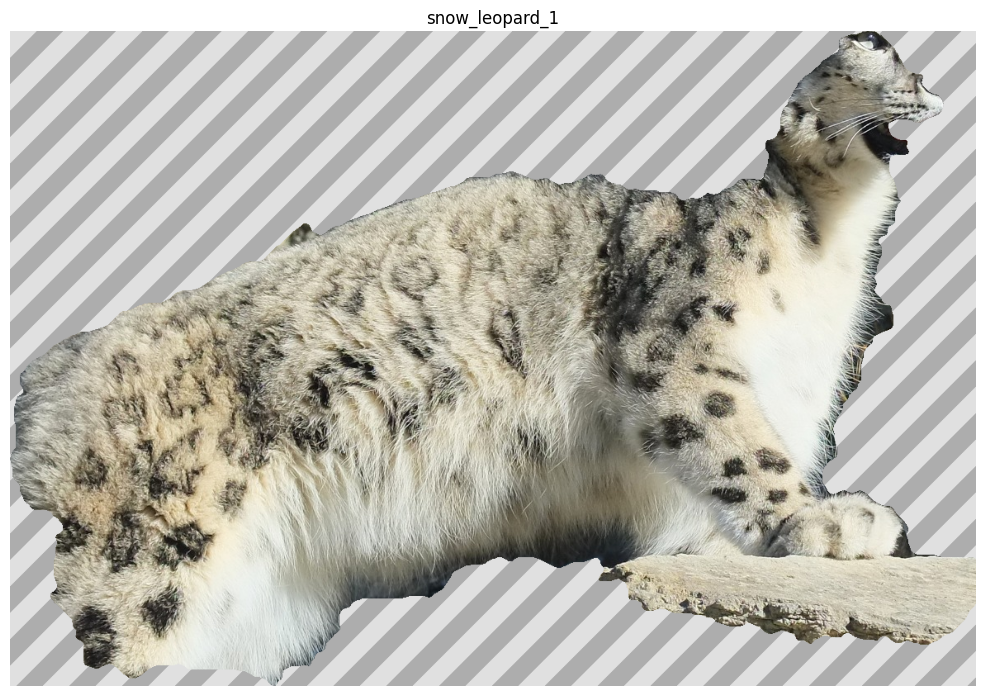

In [9]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display


def _read_q4_display(path, max_side=1400):
    image = plt.imread(path)
    scale = min(1.0, max_side / max(image.shape[:2]))
    if scale < 1.0:
        image = cv2.resize(
            image,
            (round(image.shape[1] * scale), round(image.shape[0] * scale)),
            interpolation=cv2.INTER_AREA,
        )
    return image


summary = Path("outputs/q4/summary.jpg")
figure, axis = plt.subplots(figsize=(20, 12))
axis.imshow(_read_q4_display(summary))
axis.set_title("Question 4 segmentation summary")
axis.axis("off")
figure.tight_layout()
display(figure)
plt.close(figure)

for path in sorted(Path("outputs/q4").glob("*_cropped.png")):
    rgba = _read_q4_display(path)
    height, width = rgba.shape[:2]
    checker_pattern = (np.indices((height, width)).sum(axis=0) // 32) % 2
    checkerboard = np.where(checker_pattern[..., None] == 0, 0.88, 0.68)
    checkerboard = np.repeat(checkerboard, 3, axis=2)
    figure, axis = plt.subplots(figsize=(10, 7))
    axis.imshow(checkerboard)
    axis.imshow(rgba)
    axis.set_title(path.stem.removesuffix("_cropped"))
    axis.axis("off")
    figure.tight_layout()
    display(figure)
    plt.close(figure)

### Results

| instance | mask area | clicks inside mask |
|---|---|---|
| lizard_1 | 3.0% | 3 / 3 |
| snow_leopard_1 | about 17% | 3 / 3 |
| owl_1 | 4.5% | 3 / 3 |

The code checks that every click falls inside its mask. All three instances pass.

The owl outline follows the bird. The snow leopard's torso and head do too. The lizard only comes off the bark because of the texture features. In Lab colour the two are almost the same.

The lizard's thin tail and some toes are missing. At 900 px they are a few pixels wide, and their texture matches the bark. The snow leopard mask includes the pale rock under the front paw and a small rock patch behind the back. Both are close to the belly fur in colour. The tail tip is missing too. Clicks on those parts, or one background click on the slab, would fix it. Three foreground clicks leave the slab unlabeled, and the colour match pulls it into the cat.


## AI usage

Devin, from Cognition AI, wrote and ran the code and drafted the explanations. The question chain is attached with the submission.
